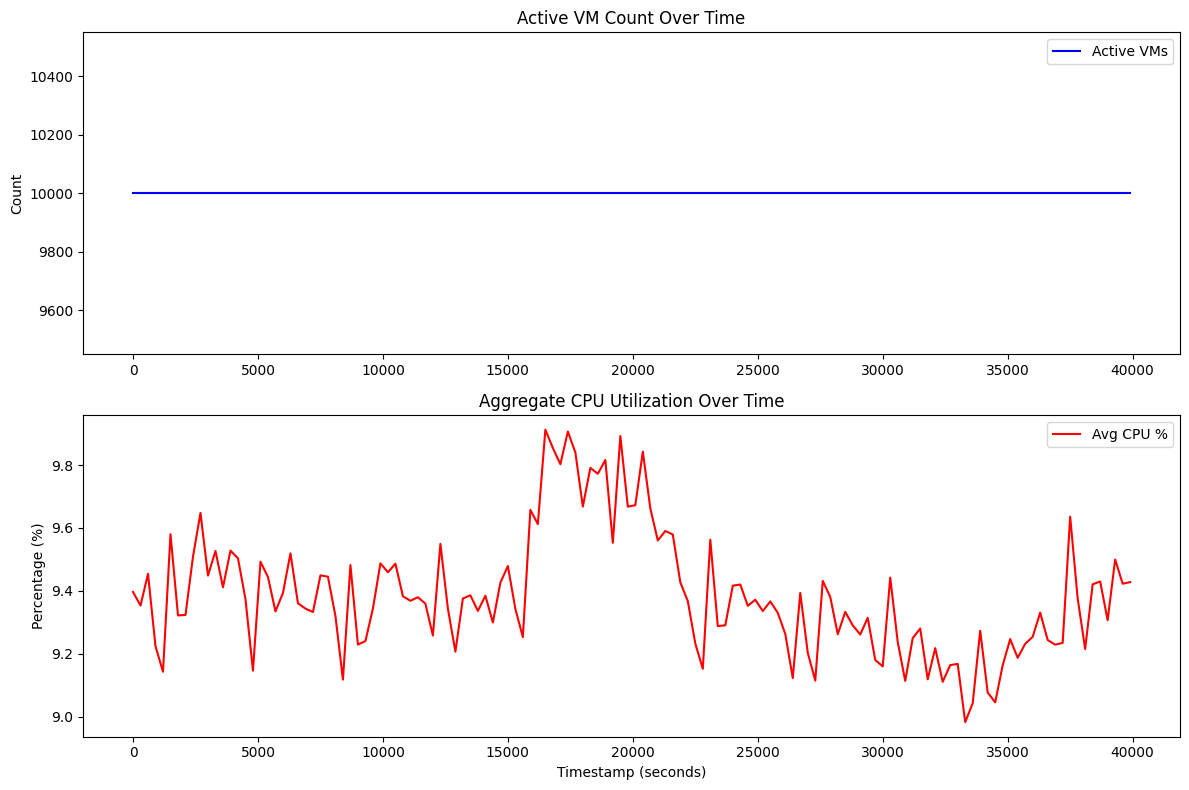

Total VMs at start: 10000
Total VMs at end: 10000
Mean CPU: 9.39%
Std Dev CPU: 0.19%


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load and aggregate data
df = pd.read_csv("../challenge_data/vm_cpu_readings.csv.gz")
active_vms = df.groupby("timestamp")["vm_id"].nunique().reset_index()
active_vms.rename(columns={"vm_id": "active_vm_count"}, inplace=True)
agg_cpu = df.groupby("timestamp")["avg_cpu"].mean().reset_index()
agg_cpu.rename(columns={"avg_cpu": "aggregate_cpu_utilization"}, inplace=True)
df_agg = pd.merge(active_vms, agg_cpu, on="timestamp").sort_values("timestamp")

# Plotting
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(df_agg["timestamp"], df_agg["active_vm_count"], color='blue', label='Active VMs')
axes[0].set_title("Active VM Count Over Time")
axes[0].set_ylabel("Count")
axes[0].legend()

axes[1].plot(df_agg["timestamp"], df_agg["aggregate_cpu_utilization"], color='red', label='Avg CPU %')
axes[1].set_title("Aggregate CPU Utilization Over Time")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_xlabel("Timestamp (seconds)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Total VMs at start: {df_agg['active_vm_count'].iloc[0]}")
print(f"Total VMs at end: {df_agg['active_vm_count'].iloc[-1]}")
print(f"Mean CPU: {df_agg['aggregate_cpu_utilization'].mean():.2f}%")
print(f"Std Dev CPU: {df_agg['aggregate_cpu_utilization'].std():.2f}%")